## Machine Failure Prediction


## step 1:Data Gathering and Data Understanding

In [50]:
import warnings
warnings.filterwarnings('ignore')

In [122]:
import pandas as pd
import numpy as np

path =r"C:\Users\PC\Downloads\train.csv"
df = pd.read_csv(path)
df.head()

,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,0,L50096,L,300.6,309.6,1596,36.1,140,0,0,0,0,0,0
1,1,M20343,M,302.6,312.1,1759,29.1,200,0,0,0,0,0,0
2,2,L49454,L,299.3,308.5,1805,26.5,25,0,0,0,0,0,0
3,3,L53355,L,301.0,310.9,1524,44.3,197,0,0,0,0,0,0
4,4,M24050,M,298.0,309.0,1641,35.4,34,0,0,0,0,0,0


In [52]:
len(df)

136429

In [53]:
df.shape

(136429, 14)

In [54]:
df.columns

Index(['id', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [55]:
df.value_counts()

id      Product ID  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  HDF  PWF  OSF  RNF
0       L50096      L     300.6                309.6                    1596                    36.1         140              0                0    0    0    0    0      1
1       M20343      M     302.6                312.1                    1759                    29.1         200              0                0    0    0    0    0      1
2       L49454      L     299.3                308.5                    1805                    26.5         25               0                0    0    0    0    0      1
3       L53355      L     301.0                310.9                    1524                    44.3         197              0                0    0    0    0    0      1
4       M24050      M     298.0                309.0                    1641                    35.4         34               0                0 

In [56]:
cols = ["Machine failure","TWF","HDF","PWF","OSF","RNF"]
print(df[cols].sum())

Machine failure    2148
TWF                 212
HDF                 704
PWF                 327
OSF                 540
RNF                 308
dtype: int64


In [57]:
df["Machine failure"].value_counts()

Machine failure
0    134281
1      2148
Name: count, dtype: int64

## Analysis
    -- Class 0(no failure) has 134,281 records
    -- Class 1(failure) has 2,148 records
    -- The dataset is highly imbalanced,as most records belongs to class 0

## Data Cleaning

In [58]:
# checking missing values 
df.isnull().sum()

id                         0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [59]:
#Checking Duplicates Rows
df.duplicated().sum()

np.int64(0)

In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 136429 entries, 0 to 136428
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       136429 non-null  int64  
 1   Product ID               136429 non-null  str    
 2   Type                     136429 non-null  str    
 3   Air temperature [K]      136429 non-null  float64
 4   Process temperature [K]  136429 non-null  float64
 5   Rotational speed [rpm]   136429 non-null  int64  
 6   Torque [Nm]              136429 non-null  float64
 7   Tool wear [min]          136429 non-null  int64  
 8   Machine failure          136429 non-null  int64  
 9   TWF                      136429 non-null  int64  
 10  HDF                      136429 non-null  int64  
 11  PWF                      136429 non-null  int64  
 12  OSF                      136429 non-null  int64  
 13  RNF                      136429 non-null  int64  
dtypes: float64(3), 

## Observation









    -- Air temperature: The average surrounding air temperature is about 300 k.
    -- Process temperature: The average machine process temperature is about 310 k.
    -- Rotational speed: The machine rotates at an average speed of 1,520.
    -- Torque: The average rotational force is 40.35 Nm.
    -- Tool Were: The average tool usage is about 104 minutes.
    -- Failure indicators: These columns contain 0 (failure type not detected)or 1 (failure type detected)
    -- Dataset completness: no missing values were found in the numerical columns.

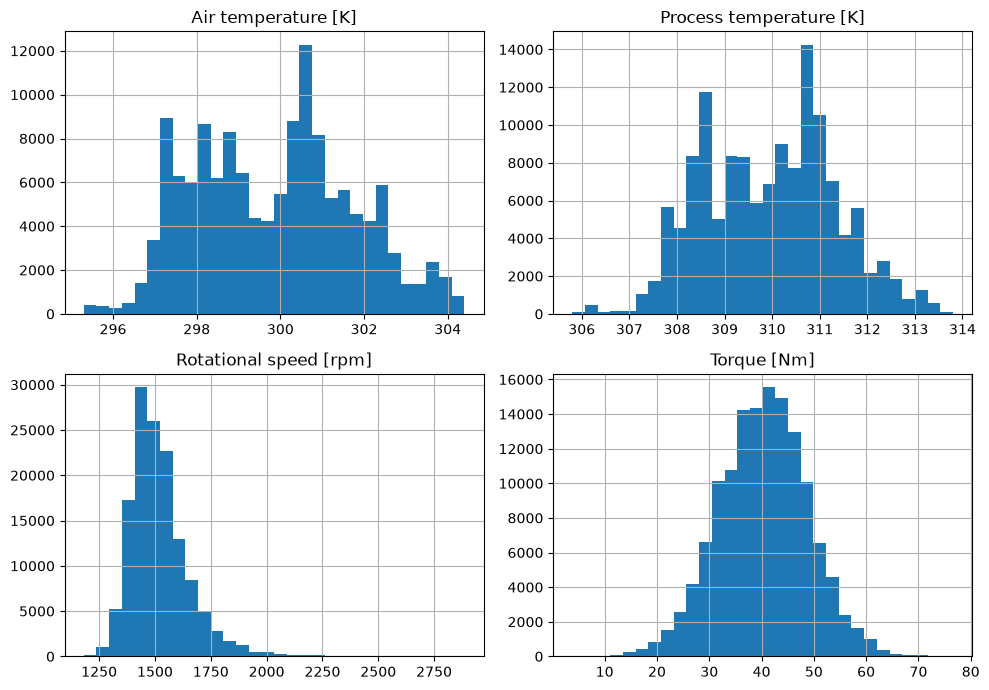

In [61]:
# Histogram
import matplotlib.pyplot as plt

cols=[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]"
]

df[cols].hist(figsize=(10,7),bins=30)
plt.tight_layout()
plt.show()

##  Observation

    1.Air Temperature: Multiple peaks;most values lies between 297-303 k.no obvious extream outliers

    2.process temperature: multiple peaks;most values lie between 308-312 k. no obvious extream outliers

    3.Rotational speed: Right-skewed;most values lie between 1,350-1,700 rpm.potential high-value outliers are present 
    
    4.Torque: Approximately normally distributed; most value lie between 30-50 Nm. some extreme vallues may be present

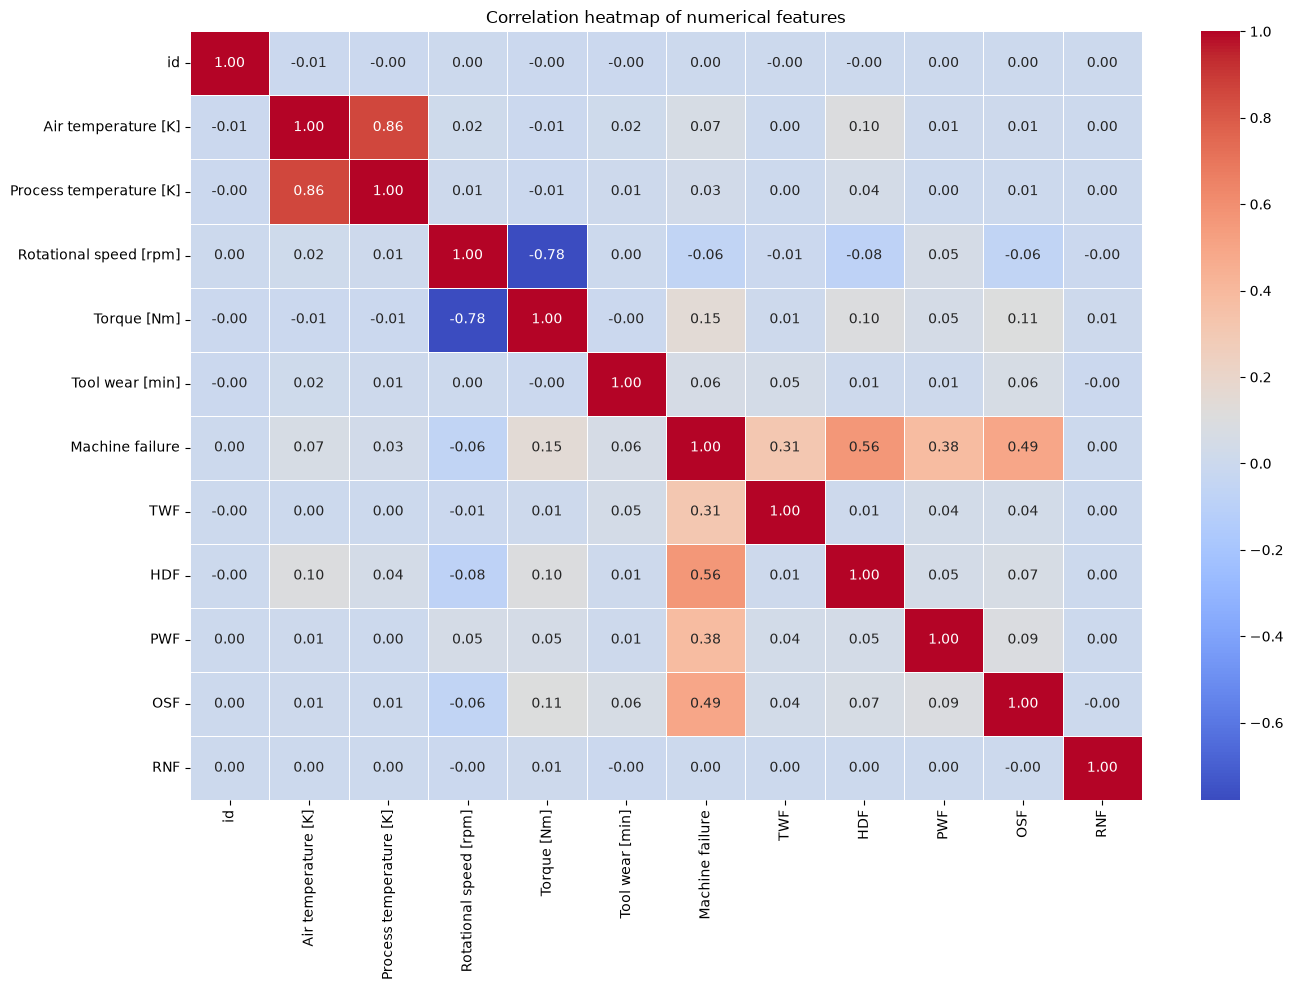

In [62]:
# Correlation heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 10))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation heatmap of numerical features")
plt.tight_layout()
plt.show()

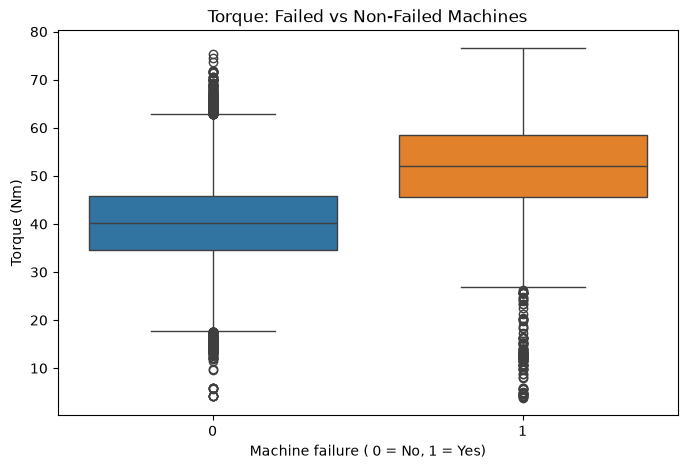

In [63]:
# Boxplot
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Torque [Nm]",
    hue="Machine failure",
    legend=False
)

plt.title("Torque: Failed vs Non-Failed Machines")
plt.xlabel("Machine failure ( 0 = No, 1 = Yes)")
plt.ylabel("Torque (Nm)")
plt.show()

In [64]:
con = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [65]:
# Outlier handling using IQR method
df_clean = df.copy()

for col in con:
  q1 = df_clean[col].quantile(0.25)
  q3 = df_clean[col].quantile(0.75)

  iqr = q3 -q1

  lower = q1 - 1.5 * iqr
  upper = q3 + 1.5 * iqr

  df_clean = df_clean [
    (df_clean[col] >= lower) &
    (df_clean[col] <= upper)
  ]

print("Original shape:", df.shape)
print("Shape after outlier removal :" ,df_clean.shape)
print("Total rows removed:",len(df) - len(df_clean))

Original shape: (136429, 14)
Shape after outlier removal : (130618, 14)
Total rows removed: 5811


##  Separate X and Y Features

In [66]:
X = df_clean.drop(columns=['id', 'Product ID', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'])

Y = df_clean[['Machine failure']]

In [67]:
display(X.shape) ,
display(Y.shape)

(130618, 6)

(130618, 1)

In [68]:
X.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,L,300.6,309.6,1596,36.1,140
1,M,302.6,312.1,1759,29.1,200
3,L,301.0,310.9,1524,44.3,197
4,M,298.0,309.0,1641,35.4,34
5,M,298.4,308.9,1429,42.1,65


In [69]:
Y.head()

,Machine failure
0,0
1,0
3,0
4,0
5,0


##  Observe whether Y data is balanced or not.

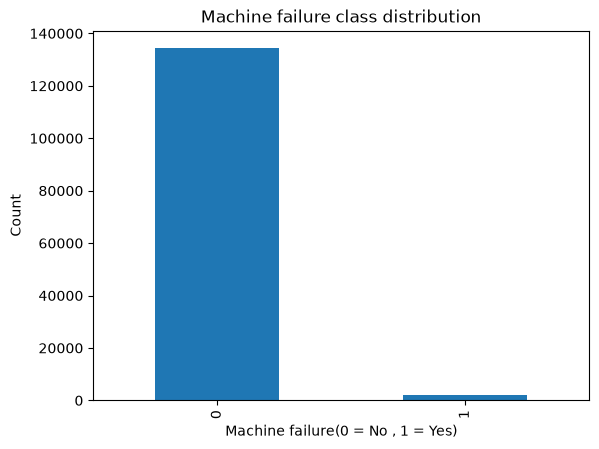

In [70]:
import matplotlib.pyplot as plt

df["Machine failure"].value_counts().plot(kind="bar")

plt.title("Machine failure class distribution")
plt.xlabel("Machine failure(0 = No , 1 = Yes)")
plt.ylabel("Count")
plt.show()

## The Dataset is the Imbalanced

Observation : The target variable Machine failure is highly imbalanced because 
 - (0)= is non-failure records
 - (1)=is higher failure records 


##  splitting the data on basis of stratified split

In [71]:
from sklearn.model_selection import train_test_split
xtrain ,xtest ,ytrain, ytest = train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)

In [72]:
xtrain.shape

(104494, 6)

In [73]:
ytrain.shape

(104494, 1)

In [74]:
xtrain.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
93832,L,300.7,309.8,1388,52.3,109
40188,L,303.3,311.3,1331,53.2,130
85597,L,301.1,311.0,1483,44.1,147
31588,M,300.4,311.6,1476,32.6,2
114552,L,300.2,309.2,1431,32.6,13


In [75]:
xtest.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
39581,L,302.9,312.4,1523,39.7,50
36570,L,300.7,310.5,1642,24.3,26
42697,L,300.6,311.6,1435,44.2,3
134963,L,298.7,309.9,1367,57.6,4
21856,L,302.3,310.1,1477,44.2,188


## Feature Engineering

In [76]:
X["Temperature Difference"]= (
    X["Process temperature [K]"] - 
    X["Air temperature [K]"]
)
(X.head())

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature Difference
0,L,300.6,309.6,1596,36.1,140,9.0
1,M,302.6,312.1,1759,29.1,200,9.5
3,L,301.0,310.9,1524,44.3,197,9.9
4,M,298.0,309.0,1641,35.4,34,11.0
5,M,298.4,308.9,1429,42.1,65,10.5


In [77]:
cat = list(xtrain.select_dtypes(include="str").columns)
con = list(xtrain.select_dtypes(include="number").columns)
print("Categorical columns:", cat)
print("Numerical columns:", con)

Categorical columns: ['Type']
Numerical columns: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [78]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

num_pipe = make_pipeline(SimpleImputer(strategy='median'),
                         StandardScaler())

cat_pipe = make_pipeline(SimpleImputer(strategy='most_frequent'),
                         OneHotEncoder(handle_unknown='ignore',sparse_output=False))

pre = ColumnTransformer([('cat',cat_pipe,cat),
                         ('con',num_pipe,con)])

pre

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('con', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [79]:
pre.fit(xtrain)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('con', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [80]:
xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

## Handling Imbalanced data using Oversampling (Resampling)

In [81]:
len(xtrain_pre)

104494

In [82]:
ytrain.value_counts()

Machine failure
0                  103097
1                    1397
Name: count, dtype: int64

In [83]:
from imblearn.over_sampling import SMOTE, ADASYN

smote = SMOTE(random_state=42)

x_sampl, y_sampl = smote.fit_resample(
    xtrain_pre, ytrain
)

In [84]:
len(y_sampl)

206194

In [85]:
y_sampl.value_counts()

Machine failure
0                  103097
1                  103097
Name: count, dtype: int64

##  Model Building 

## Algorithm Evaluation

In [86]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

In [87]:
dct = {
    'Logistic' : LogisticRegression(max_iter=2000),
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'RandomForest' : RandomForestClassifier(random_state=42, n_jobs=-1),
    'GradientBoosting' : GradientBoostingClassifier(random_state=42),
    'XGBoost' : XGBClassifier(random_state=42, eval_metric="logloss")
                              
}

In [88]:
roc_scores = []

for name,model in dct.items(): # key value pairs

    # Fit the model
    model.fit(x_sampl,y_sampl)

    # Predict the results
    if hasattr(model,"predict_proba"):
        y_score = model.predict_proba(xtest_pre)[:,1]
    else:
        y_score = model.decision_function(xtest_pre)

    # Calculate ROC-AUC 
    auc = roc_auc_score(ytest,y_score)
    roc_scores.append(round(auc,3))

    print(name,"ROC-Score:",round(auc,3))

print("ROC-Score:",roc_scores)

Logistic ROC-Score: 0.871
DecisionTree ROC-Score: 0.688
RandomForest ROC-Score: 0.908
GradientBoosting ROC-Score: 0.924
XGBoost ROC-Score: 0.911
ROC-Score: [0.871, 0.688, 0.908, 0.924, 0.911]


In [89]:
res = {
    'Name':list(dct.keys()),
    'ROC_score': roc_scores
}
df_res = pd.DataFrame(res)
df_res.sort_values(by='ROC_score',ascending=False)

,Name,ROC_score
3,GradientBoosting,0.924
4,XGBoost,0.911
2,RandomForest,0.908
0,Logistic,0.871
1,DecisionTree,0.688


## Gradient Boosting has the highest ROC-AUC score(0.924) we consider this model for final deployment

## Hyperparameter Tunning

In [90]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import roc_auc_score
from imblearn.over_sampling import SMOTE
from sklearn.pipeline import Pipeline

In [91]:
from imblearn.pipeline import Pipeline

In [92]:
## Create  Model 
GC = GradientBoostingClassifier(random_state=42)

In [93]:
#Hyperparameters
param_grid = {
    "model__n_estimators": [100, 150, 200],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [2, 3, 5],
    "model__subsample" : [0.8, 1.0]
}

In [94]:
print(list(param_grid.keys()))

['model__n_estimators', 'model__learning_rate', 'model__max_depth', 'model__subsample']


In [95]:
# Create Pipeline
pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", GC)
])

In [96]:
# Configure Hyperparameter tuning
random_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_grid,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score='raise'
)

In [97]:
random_search.fit(xtrain_pre , ytrain)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__learning_rate': [0.01, 0.05, ...], 'model__max_depth': [2, 3, ...], 'model__n_estimators': [100, 150, ...], 'model__subsample': [0.8, 1.0]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using th

In [98]:
gb = random_search.best_estimator_

In [99]:
print(random_search.best_params_)

{'model__subsample': 1.0, 'model__n_estimators': 100, 'model__max_depth': 2, 'model__learning_rate': 0.05}


In [100]:
print(random_search.best_score_)

0.911634218330267


In [101]:
y_pred = gb.predict(xtest_pre)

In [102]:
y_score = gb.predict_proba(xtest_pre)[:,1]

## Evalution Metrics

In [103]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(ytest, y_pred))
print("Permission:",precision_score(ytest,y_pred,zero_division=0))
print("Recall:",recall_score(ytest,y_pred,zero_division=0))
print("F1-score:",f1_score(ytest,y_pred,zero_division=0)) 
print("ROC - AUC:",roc_auc_score(ytest,y_score))

print("\nClassification Report:")
print(classification_report(ytest,y_pred,zero_division=0))

print("\nConfusion Metrix:")
print(confusion_matrix(ytest,y_pred))

Accuracy: 0.8566452304394426
Permission: 0.07528764382191096
Recall: 0.8624641833810889
F1-score: 0.13848631239935588
ROC - AUC: 0.9219552608394777

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.86      0.92     25775
           1       0.08      0.86      0.14       349

    accuracy                           0.86     26124
   macro avg       0.54      0.86      0.53     26124
weighted avg       0.99      0.86      0.91     26124


Confusion Metrix:
[[22078  3697]
 [   48   301]]


## Confusion metrics

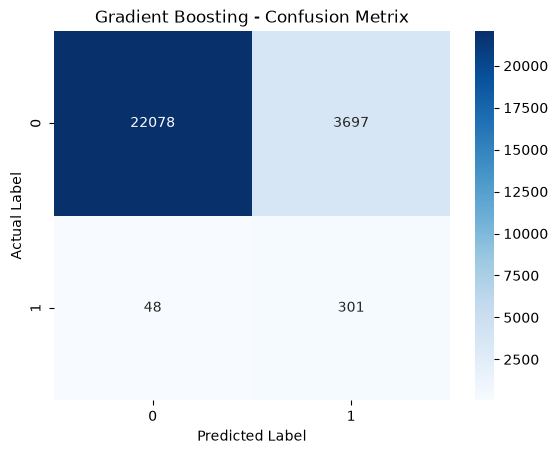

In [104]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(ytest,y_pred)

sns.heatmap(cm,annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Gradient Boosting - Confusion Metrix")
plt.show()

## ROC Curve

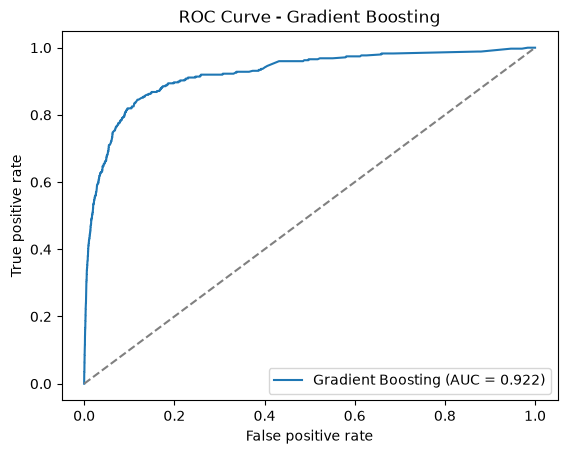

In [105]:
from sklearn.metrics import roc_curve,roc_auc_score

fpr, tpr ,thresholds = roc_curve(ytest,y_score)
auc = roc_auc_score(ytest,y_score)

plt.plot(fpr ,tpr , label=f"Gradient Boosting (AUC = {auc:.3f})")
plt.plot([0,1],[0,1], linestyle="--", color="gray")

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curve - Gradient Boosting")
plt.legend()
plt.show()

In [106]:
print("Best CV ROC - AUC:",random_search.best_score_)
print("Best Parameters:",random_search.best_params_)

Best CV ROC - AUC: 0.911634218330267
Best Parameters: {'model__subsample': 1.0, 'model__n_estimators': 100, 'model__max_depth': 2, 'model__learning_rate': 0.05}


## Save the finalized model and Pipeline

In [107]:
import joblib
#Save Model 
joblib.dump(gb,"gradient_boosting_model.joblib")

#Save processing pipeline
joblib.dump(pre,"preprocessing_pipeline.joblib")

['preprocessing_pipeline.joblib']

## Data Gathering from test.csv

In [109]:
test = pd.read_csv(r"C:\Users\PC\Downloads\test.csv")
test.head()

,id,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],TWF,HDF,PWF,OSF,RNF
0,136429,L50896,L,302.3,311.5,1499,38.0,60,0,0,0,0,0
1,136430,L53866,L,301.7,311.0,1713,28.8,17,0,0,0,0,0
2,136431,L50498,L,301.3,310.4,1525,37.7,96,0,0,0,0,0
3,136432,M21232,M,300.1,309.6,1479,47.6,5,0,0,0,0,0
4,136433,M19751,M,303.4,312.3,1515,41.3,114,0,0,0,0,0


In [110]:
# Same six features used during training

xnew = test[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
]
(xnew.head())

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,L,302.3,311.5,1499,38.0,60
1,L,301.7,311.0,1713,28.8,17
2,L,301.3,310.4,1525,37.7,96
3,M,300.1,309.6,1479,47.6,5
4,M,303.4,312.3,1515,41.3,114


In [111]:
xnew_pre = pre.transform(xnew)
xnew_pre

array([[ 0.        ,  1.        ,  0.        , ..., -0.04877523,
        -0.37791785, -0.69528042],
       [ 0.        ,  1.        ,  0.        , ...,  1.99114029,
        -1.57482228, -1.3690052 ],
       [ 0.        ,  1.        ,  0.        , ...,  0.19906497,
        -0.41694734, -0.13123176],
       ...,
       [ 0.        ,  1.        ,  0.        , ..., -0.0297106 ,
         0.06441639,  1.2945579 ],
       [ 0.        ,  1.        ,  0.        , ...,  0.28485581,
        -0.07869175, -0.55426825],
       [ 0.        ,  1.        ,  0.        , ...,  0.28485581,
        -0.62510464, -0.19390383]], shape=(90954, 8))

In [112]:
gb = random_search.best_estimator_

In [113]:
xnew_pre = pre.transform(xnew)

In [114]:
predictions = gb.predict(xnew_pre)
predictions

array([0, 0, 0, ..., 0, 0, 0], shape=(90954,))

In [115]:
xnew['Machine failure'] = predictions
xnew

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,L,302.3,311.5,1499,38.0,60,0
1,L,301.7,311.0,1713,28.8,17,0
2,L,301.3,310.4,1525,37.7,96,0
3,M,300.1,309.6,1479,47.6,5,0
4,M,303.4,312.3,1515,41.3,114,0
...,...,...,...,...,...,...,...
90949,L,302.3,311.4,1484,40.4,15,0
90950,L,297.9,309.8,1542,33.8,31,0
90951,L,295.6,306.2,1501,41.4,187,0
90952,L,298.1,307.8,1534,40.3,69,0


In [116]:
y_score = gb.predict_proba(xnew_pre)[:,1]

print(y_score.min())
print(y_score.max())
print(y_score.mean())

0.05779682834123503
0.9795264178426499
0.24578136876462148


In [123]:
predictions_05 =(y_score >= 0.5).astype(int)

print("Prediction Counts:")
print(np.unique(predictions_05,return_counts=True))

Prediction Counts:
(array([0, 1]), array([77335, 13619]))


In [119]:
# Save the final prediction file

test["Predicted Machine Failure"]= predictions_05
test.to_csv("machine_failure_predictions.csv",index=False)